In [ ]:
import random

def fitness(x):
    return x * x - 4 * x + 4


def get_neighbors(grid, row, col, size):
    neighbors = []

    for i in range(max(0, row - 1), min(size, row + 2)):
        for j in range(max(0, col - 1), min(size, col + 2)):
            if i != row or j != col:
                neighbors.append(grid[i][j])

    return neighbors


def main():
    size = 5
    iterations = 10
    lower = -10
    upper = 10

    random.seed(10)

    grid = [
        [random.uniform(lower, upper) for _ in range(size)]
        for _ in range(size)
    ]

    best_x = None
    best_fitness = float('inf')

    for iteration in range(1, iterations + 1):

        new_grid = [[0 for _ in range(size)] for _ in range(size)]

        for i in range(size):
            for j in range(size):

                current = grid[i][j]
                neighbors = get_neighbors(grid, i, j, size)

                candidates = neighbors + [current]

                best_neighbor = min(
                    candidates,
                    key=fitness
                )

                # Move towards the best neighboring solution
                new_value = (
                    current + best_neighbor
                ) / 2

                # Small random exploration
                new_value += random.uniform(-0.2, 0.2)

                # Keep value inside search space
                new_value = max(lower, min(upper, new_value))

                new_grid[i][j] = new_value

        grid = new_grid

        # Find best cell in current iteration
        current_best = min(
            (grid[i][j] for i in range(size) for j in range(size)),
            key=fitness
        )

        current_fitness = fitness(current_best)

        if current_fitness < best_fitness:
            best_fitness = current_fitness
            best_x = current_best

        print("\nIteration", iteration)
        print("-" * 45)

        for row in grid:
            print(" ".join(f"{x:7.3f}" for x in row))

        print(f"Best x       = {current_best:.5f}")
        print(f"Best fitness = {current_fitness:.5f}")

    print("\nFinal Best Solution")
    print("-" * 45)
    print(f"x = {best_x:.5f}")
    print(f"f(x) = {best_fitness:.5f}")


if __name__ == "__main__":
    main()


Iteration 1
---------------------------------------------
  1.616   0.115   1.380  -2.356   3.193
  4.126   2.237  -2.670   1.147  -1.590
 -1.449   5.534   6.326  -2.771   5.489
  1.926  -0.262  -0.580   3.314   1.317
  3.018   2.714  -2.038   4.570   6.434
Best x       = 1.92638
Best fitness = 0.00542

Iteration 2
---------------------------------------------
  1.953   1.126   1.849  -0.643   2.280
  3.020   2.103  -0.094   1.442  -0.248
  0.205   3.629   4.191  -0.680   3.274
  1.774   0.814   0.933   2.375   1.445
  2.583   2.312   0.277   2.917   3.677
Best x       = 1.95319
Best fitness = 0.00219

Iteration 3
---------------------------------------------
  2.038   1.472   1.904   0.435   2.260
  2.520   1.984   1.153   1.715   0.913
  1.164   3.030   3.155   0.888   2.650
  1.770   1.279   1.583   2.343   1.944
  2.194   2.039   1.161   2.623   3.213
Best x       = 1.98449
Best fitness = 0.00024

Iteration 4
---------------------------------------------
  1.977   1.542   1.745   

Executing Parallel Cellular Algorithm on Device: cpu
PARALLEL CELLULAR ALGORITHM OPTIMIZATION RESULTS
Execution Device       : cpu
Grid Dimensions          : 20 x 20 (400 Active Cells)
Neighborhood Structure   : Moore (8-Connected Torus)
Problem Dimensions       : 10
Max Generations          : 200
Total Execution Time     : 0.7239 Seconds
----------------------------------------------------------------------
Initial Best Fitness     : 83.530289
Final Best Fitness       : 9.862160e+00

Optimal Decision Vector (x*):
[-0.04516453 -0.11513492 -0.08161715  0.06838926  0.91066384  0.00455
 -0.06420347  0.07984498  0.0322951  -0.02421791]


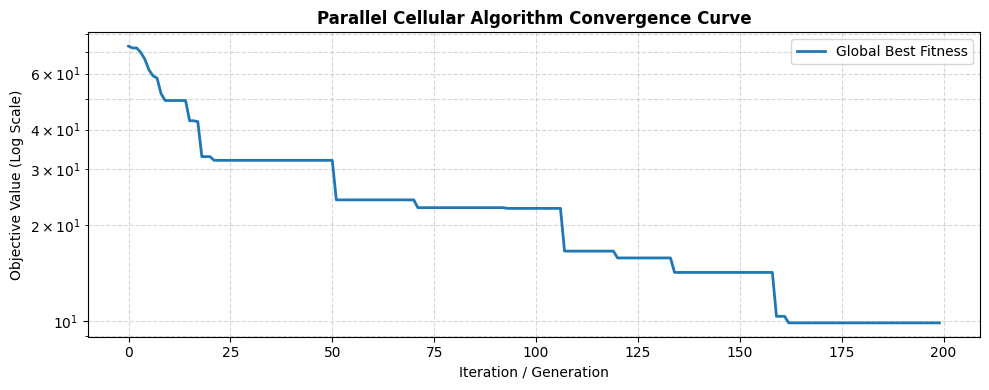

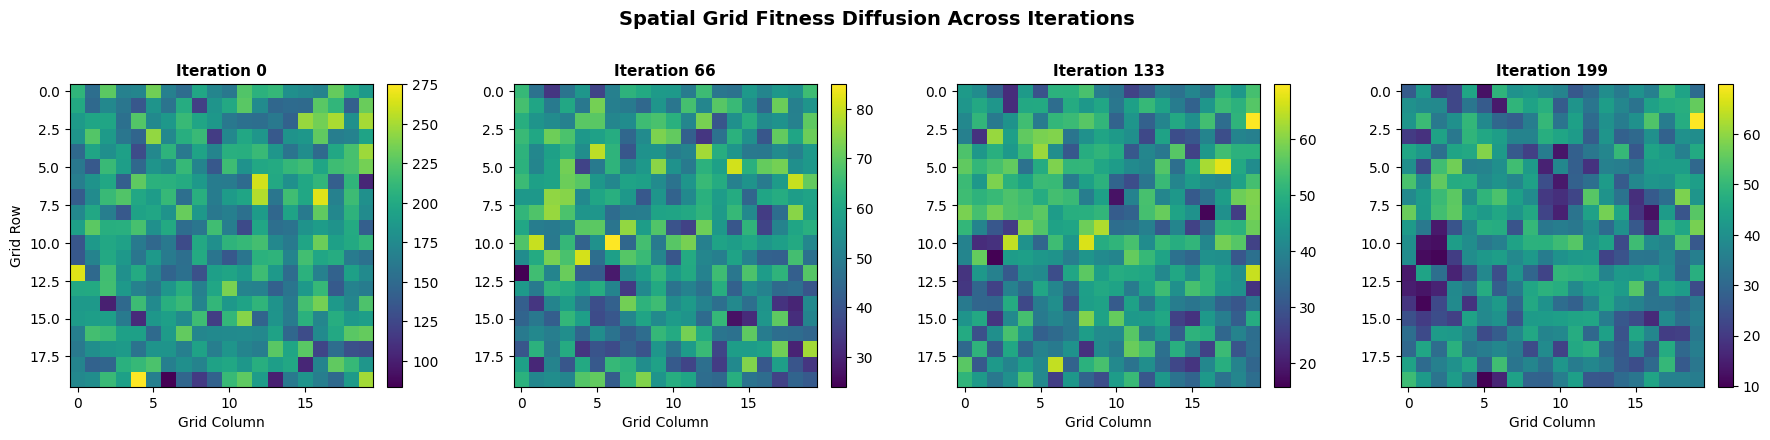

In [1]:
import time
import torch
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# DEVICE CONFIGURATION
# ==============================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing Parallel Cellular Algorithm on Device: {device}")

# ==============================================================================
# STEP 1: DEFINE OBJECTIVE FUNCTIONS (Batched Tensor Input)
# ==============================================================================
def sphere_function(x: torch.Tensor) -> torch.Tensor:
    """
    Unimodal Sphere Benchmark: f(x) = sum(x_i^2)
    Global Minimum: f(0, ..., 0) = 0.0
    """
    return torch.sum(x**2, dim=-1)

def rastrigin_function(x: torch.Tensor) -> torch.Tensor:
    """
    Multimodal Rastrigin Benchmark: f(x) = 10d + sum(x_i^2 - 10*cos(2*pi*x_i))
    Global Minimum: f(0, ..., 0) = 0.0
    """
    d = x.shape[-1]
    return 10 * d + torch.sum(x**2 - 10 * torch.cos(2 * torch.pi * x), dim=-1)

# ==============================================================================
# STEPS 2-7: PARALLEL CELLULAR ALGORITHM ENGINE
# ==============================================================================
class ParallelCellularAlgorithm:
    def __init__(
        self,
        objective_func,
        dim: int = 10,
        bounds: tuple = (-5.12, 5.12),
        grid_shape: tuple = (20, 20),
        max_iter: int = 200,
        F: float = 0.5,
        CR: float = 0.8
    ):
        self.func = objective_func
        self.dim = dim
        self.bounds = bounds
        self.R, self.C = grid_shape
        self.max_iter = max_iter
        self.F = F
        self.CR = CR

        # 8-Directional Offsets for Moore Neighborhood
        self.offsets = [
            (-1, 0), (1, 0), (0, -1), (0, 1),   # von Neumann (N, S, W, E)
            (-1, -1), (-1, 1), (1, -1), (1, 1)  # Diagonals (NW, NE, SW, SE)
        ]

    def optimize(self):
        start_time = time.time()

        # STEP 3: INITIALIZE POPULATION GRID (R x C x dim)
        lower, upper = self.bounds
        P = torch.rand(self.R, self.C, self.dim, device=device) * (upper - lower) + lower

        # STEP 4: EVALUATE INITIAL FITNESS GRID (R x C)
        F_grid = self.func(P)

        # Track initial metrics
        initial_best_f = torch.min(F_grid).item()
        history_best_f = []
        heatmap_snapshots = {}

        snapshot_intervals = [0, self.max_iter // 3, (2 * self.max_iter) // 3, self.max_iter - 1]

        # Global best tracking
        min_flat_idx = torch.argmin(F_grid)
        best_r, best_c = divmod(min_flat_idx.item(), self.C)
        global_best_f = F_grid[best_r, best_c].item()
        global_best_x = P[best_r, best_c].clone()

        # STEP 5 & 6: ITERATIVE STATE UPDATES & SYNCHRONIZATION
        for iteration in range(self.max_iter):
            # Capture spatial grid snapshot for visualization
            if iteration in snapshot_intervals:
                heatmap_snapshots[iteration] = F_grid.cpu().numpy().copy()

            # Construct Moore Neighborhood Tensors via Toroidal Rolls
            # Tensor Shape: (9, R, C, dim) where index 0 is center cell
            stacked_P = torch.stack(
                [P] + [torch.roll(P, shifts=off, dims=(0, 1)) for off in self.offsets],
                dim=0
            )
            stacked_F = torch.stack(
                [F_grid] + [torch.roll(F_grid, shifts=off, dims=(0, 1)) for off in self.offsets],
                dim=0
            )

            # Find Local Best Neighbor per Cell
            local_best_indices = torch.argmin(stacked_F, dim=0) # Shape: (R, C)
            local_best_P = torch.gather(
                stacked_P, 0, local_best_indices.unsqueeze(0).unsqueeze(-1).expand(1, self.R, self.C, self.dim)
            ).squeeze(0)

            # Select 2 Random Distinct Neighbors per Cell from the 8 Moore Neighbors
            neighbors_P_only = stacked_P[1:] # Shape: (8, R, C, dim)
            idx1 = torch.randint(0, 8, (self.R, self.C), device=device)
            idx2 = (idx1 + torch.randint(1, 8, (self.R, self.C), device=device)) % 8

            r1_P = torch.gather(neighbors_P_only, 0, idx1.unsqueeze(0).unsqueeze(-1).expand(1, self.R, self.C, self.dim)).squeeze(0)
            r2_P = torch.gather(neighbors_P_only, 0, idx2.unsqueeze(0).unsqueeze(-1).expand(1, self.R, self.C, self.dim)).squeeze(0)

            # Generate Trial State (Mutation: Target-to-Local-Best Scheme)
            V = P + self.F * (local_best_P - P) + self.F * (r1_P - r2_P)

            # Apply Binomial Crossover
            crossover_mask = torch.rand(self.R, self.C, self.dim, device=device) < self.CR
            j_rand = torch.randint(0, self.dim, (self.R, self.C), device=device)
            crossover_mask.scatter_(-1, j_rand.unsqueeze(-1), True) # Ensure >= 1 dimension updates

            Trial_P = torch.where(crossover_mask, V, P)
            Trial_P = torch.clamp(Trial_P, lower, upper)
            Trial_F = self.func(Trial_P)

            # Local Selection (Elitist Replacement)
            improved_mask = Trial_F <= F_grid
            P = torch.where(improved_mask.unsqueeze(-1), Trial_P, P)
            F_grid = torch.where(improved_mask, Trial_F, F_grid)

            # Update Global Best
            current_min_val, current_min_idx = torch.min(F_grid.view(-1), dim=0)
            if current_min_val.item() < global_best_f:
                global_best_f = current_min_val.item()
                cr, cc = divmod(current_min_idx.item(), self.C)
                global_best_x = P[cr, cc].clone()

            history_best_f.append(global_best_f)

        # Final Snapshot
        heatmap_snapshots[self.max_iter - 1] = F_grid.cpu().numpy().copy()
        elapsed_time = time.time() - start_time

        # STEP 7: OUTPUT METRICS & RESULTS
        print("=" * 70)
        print("PARALLEL CELLULAR ALGORITHM OPTIMIZATION RESULTS")
        print("=" * 70)
        print(f"Execution Device       : {device}")
        print(f"Grid Dimensions          : {self.R} x {self.C} ({self.R * self.C} Active Cells)")
        print(f"Neighborhood Structure   : Moore (8-Connected Torus)")
        print(f"Problem Dimensions       : {self.dim}")
        print(f"Max Generations          : {self.max_iter}")
        print(f"Total Execution Time     : {elapsed_time:.4f} Seconds")
        print("-" * 70)
        print(f"Initial Best Fitness     : {initial_best_f:.6f}")
        print(f"Final Best Fitness       : {global_best_f:.6e}")
        print("\nOptimal Decision Vector (x*):")
        print(global_best_x.cpu().numpy())
        print("=" * 70)

        return history_best_f, heatmap_snapshots

# ==============================================================================
# EXECUTION & VISUALIZATION PIPELINE
# ==============================================================================
if __name__ == "__main__":
    # Choose Objective Function: sphere_function OR rastrigin_function
    target_func = rastrigin_function
    bounds = (-5.12, 5.12)
    max_generations = 200

    pca = ParallelCellularAlgorithm(
        objective_func=target_func,
        dim=10,
        bounds=bounds,
        grid_shape=(20, 20),
        max_iter=max_generations,
        F=0.5,
        CR=0.8
    )

    history, heatmaps = pca.optimize()

    # 1. Plot Convergence History
    plt.figure(figsize=(10, 4))
    plt.plot(history, color='#1f77b4', linewidth=2, label='Global Best Fitness')
    plt.yscale('log')
    plt.title('Parallel Cellular Algorithm Convergence Curve', fontsize=12, fontweight='bold')
    plt.xlabel('Iteration / Generation', fontsize=10)
    plt.ylabel('Objective Value (Log Scale)', fontsize=10)
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 2. Plot Spatial Grid Diffusion Heatmaps
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    snapshot_keys = sorted(heatmaps.keys())

    for idx, key in enumerate(snapshot_keys):
        im = axes[idx].imshow(heatmaps[key], cmap='viridis', origin='upper')
        axes[idx].set_title(f'Iteration {key}', fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('Grid Column')
        if idx == 0:
            axes[idx].set_ylabel('Grid Row')
        fig.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

    plt.suptitle('Spatial Grid Fitness Diffusion Across Iterations', fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()


========== CELLULAR AUTOMATON DATA ==========

       0  1  2  3  4  5  6  7  8  9  10  11  12  13  14  15  16
gen 0  0  0  0  0  0  0  0  0  1  0   0   0   0   0   0   0   0
gen 1  0  0  0  0  0  0  0  1  0  1   0   0   0   0   0   0   0
gen 2  0  0  0  0  0  0  1  0  0  0   1   0   0   0   0   0   0
gen 3  0  0  0  0  0  1  0  1  0  1   0   1   0   0   0   0   0
gen 4  0  0  0  0  1  0  0  0  0  0   0   0   1   0   0   0   0
gen 5  0  0  0  1  0  1  0  0  0  0   0   1   0   1   0   0   0
gen 6  0  0  1  0  0  0  1  0  0  0   1   0   0   0   1   0   0
gen 7  0  1  0  1  0  1  0  1  0  1   0   1   0   1   0   1   0
gen 8  1  0  0  0  0  0  0  0  0  0   0   0   0   0   0   0   1

========== GENERATIONS ==========

gen 0 : 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 
gen 1 : 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 
gen 2 : 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 
gen 3 : 0 0 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 
gen 4 : 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 
gen 5 : 0 0 0 1 0 1 0 0 0 0 0 1 0 1 0 0 0 
gen 6 : 0 0 1 0 0 

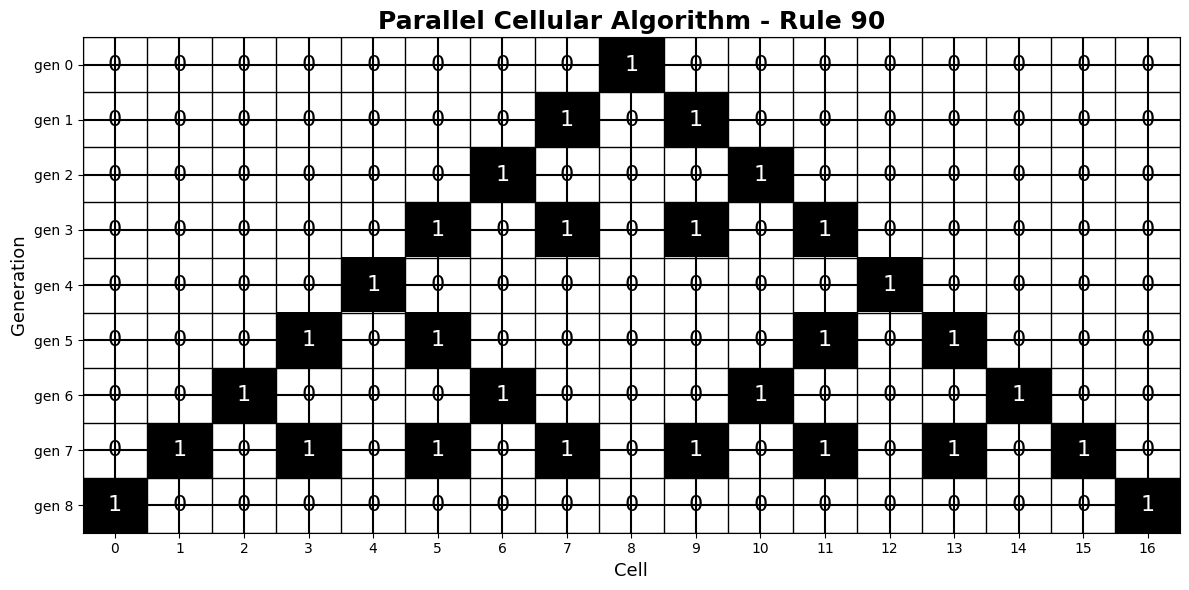

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------
# Parameters
# -----------------------------------------
ROWS = 9
COLS = 17

# -----------------------------------------
# Initial generation
# Single 1 in the center
# -----------------------------------------
grid = np.zeros((ROWS, COLS), dtype=int)

grid[0, COLS // 2] = 1


# -----------------------------------------
# Rule 90 Cellular Automaton
#
# New cell = Left XOR Right
#
# 1 1 -> 0
# 1 0 -> 1
# 0 1 -> 1
# 0 0 -> 0
# -----------------------------------------

for generation in range(1, ROWS):

    previous = grid[generation - 1]

    for j in range(COLS):

        # Left neighbor
        if j == 0:
            left = 0
        else:
            left = previous[j - 1]

        # Right neighbor
        if j == COLS - 1:
            right = 0
        else:
            right = previous[j + 1]

        # Rule 90
        grid[generation][j] = left ^ right


# -----------------------------------------
# Display data as a table
# -----------------------------------------

print("\n========== CELLULAR AUTOMATON DATA ==========\n")

df = pd.DataFrame(
    grid,
    index=[f"gen {i}" for i in range(ROWS)],
    columns=[f"{i}" for i in range(COLS)]
)

print(df.to_string())


# -----------------------------------------
# Print generation-wise output
# Similar to the image
# -----------------------------------------

print("\n========== GENERATIONS ==========\n")

for i in range(ROWS):
    print(f"gen {i} : ", end="")

    for value in grid[i]:
        print(value, end=" ")

    print()


# -----------------------------------------
# Heatmap
# -----------------------------------------

plt.figure(figsize=(12, 6))

plt.imshow(
    grid,
    cmap="binary",
    interpolation="nearest",
    aspect="auto"
)

# -----------------------------------------
# Add 0 and 1 inside every cell
# -----------------------------------------

for i in range(ROWS):
    for j in range(COLS):
        plt.text(
            j,
            i,
            str(grid[i, j]),
            ha="center",
            va="center",
            fontsize=16,
            color="black" if grid[i, j] == 0 else "white"
        )


# -----------------------------------------
# Grid lines
# -----------------------------------------

plt.xticks(
    np.arange(COLS),
    np.arange(COLS)
)

plt.yticks(
    np.arange(ROWS),
    [f"gen {i}" for i in range(ROWS)]
)

plt.grid(
    which="major",
    color="black",
    linestyle="-",
    linewidth=1.5
)

# Put grid lines between cells
plt.gca().set_xticks(
    np.arange(-0.5, COLS, 1),
    minor=True
)

plt.gca().set_yticks(
    np.arange(-0.5, ROWS, 1),
    minor=True
)

plt.grid(
    which="minor",
    color="black",
    linestyle="-",
    linewidth=1
)

plt.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# -----------------------------------------
# Labels and title
# -----------------------------------------

plt.title(
    "Parallel Cellular Algorithm - Rule 90",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Cell", fontsize=13)
plt.ylabel("Generation", fontsize=13)

plt.tight_layout()
plt.show()